In [4]:
from requirements import *
from utils.tl.deg import runDEseq

# Extended Data Figure 11

In [5]:
adata_xenv2 = sc.read_h5ad(XEN_V2)

## ED Figure 11a. Mutant Probe QC


In [3]:
probe_di = {'SRSF2': ['NM_001195427_ALT_283:'], 'IDH1': ['NM_005896_ALT_394:A'],
            'U2AF1': ['NM_006758_ALT_100:T'],
           'SF3B1': ['NM_012433_ALT_2097:G', 'ORAI2_e1_alt_e2', 'ZDHHC16_e9_alt_e10'],
           'ASXL1': ['NM_015338_ALT_1899:'], 'DNMT3A': ['NM_022552_ALT_1237:GG', 'NM_022552_ALT_1875:'],
           'CUX1': ['NM_181552_ALT_364:TT']}

sample_mutation_di = {'U2AF1': ['region1_0033266','region1_0065644','region2_0065644','region1_0065647','region2_0065647'], 'ASXL1': ['region1_0033266'],
                      'IDH1': ['region1_0033082'], 'SRSF2': ['region1_0033082'], 'CUX1': ['region1_0033082'],
                      'DNMT3A': ['region1_0033134'], 'SF3B1': ['region1_0033274', 'region1_0033485', 'region2_0043245', 'region2_0043233', 'region1_0065586']}

df_probe = None
for mutation in probe_di:
    mutsamples = sample_mutation_di[mutation]
    print(mutsamples)
    for probe in probe_di[mutation]:
        print(probe)
        df = sc.get.obs_df(adata_xenv2, keys=[probe, 'sample_name', 'ct_general'], use_raw= True)
        df = df.iloc[:,0:2]
        df.columns = ['mut','sample']
        cutoff = []
        fpr = []
        num = []
        for i in range(int(max(df['mut']) + 1)):
            print(i)
            cutoff.append(str(i))
            num.append(sum(df.loc[df['sample'].isin(mutsamples)]['mut'] >= i))
            if sum(df.loc[df['sample'].isin(mutsamples)]['mut'] >= i) == 0:
                fpr.append(1)
            else:
                expected_falsepos = (sum(df.loc[~(df['sample'].isin(mutsamples))]['mut'] >= i)/df.loc[~(df['sample'].isin(mutsamples))].shape[0]) * df.loc[df['sample'].isin(mutsamples)].shape[0]
                val = expected_falsepos/sum(df.loc[df['sample'].isin(mutsamples)]['mut'] >= i) # proportion of positives that are expected to be false positives
                fpr.append(min(val,1))
        currdf = pd.DataFrame(list(zip(cutoff, fpr, num)),columns=['Probe Quantity Cutoff', 'Predicted FDR', 'Mutant Cells'])
        currdf['Mutant Probe'] = probe
        currdf['Mutation'] = mutation
        df_probe = pd.concat([df_probe, currdf])

df_probe.reset_index(drop=True, inplace=True)
df_probe['cutoff'] = [int(x) for x in df_probe['Probe Quantity Cutoff']]
df_probe['log10(Mutant Cells)'] = np.log10(df_probe['Mutant Cells'])


['region1_0033082']
NM_001195427_ALT_283:
0
1
2
3
['region1_0033082']
NM_005896_ALT_394:A
0
1
2
['region1_0033266', 'region1_0065644', 'region2_0065644', 'region1_0065647', 'region2_0065647']
NM_006758_ALT_100:T
0
1
2
3
4
['region1_0033274', 'region1_0033485', 'region2_0043245', 'region2_0043233', 'region1_0065586']
NM_012433_ALT_2097:G
0
1
2
3
4
5
6
7
ORAI2_e1_alt_e2
0
1
2
3
ZDHHC16_e9_alt_e10
0
1
2
['region1_0033266']
NM_015338_ALT_1899:
0
1
2
3
['region1_0033134']
NM_022552_ALT_1237:GG
0
1
NM_022552_ALT_1875:
0
1
2
3
4
5
6
7
8
9
['region1_0033082']
NM_181552_ALT_364:TT
0
1
2
3


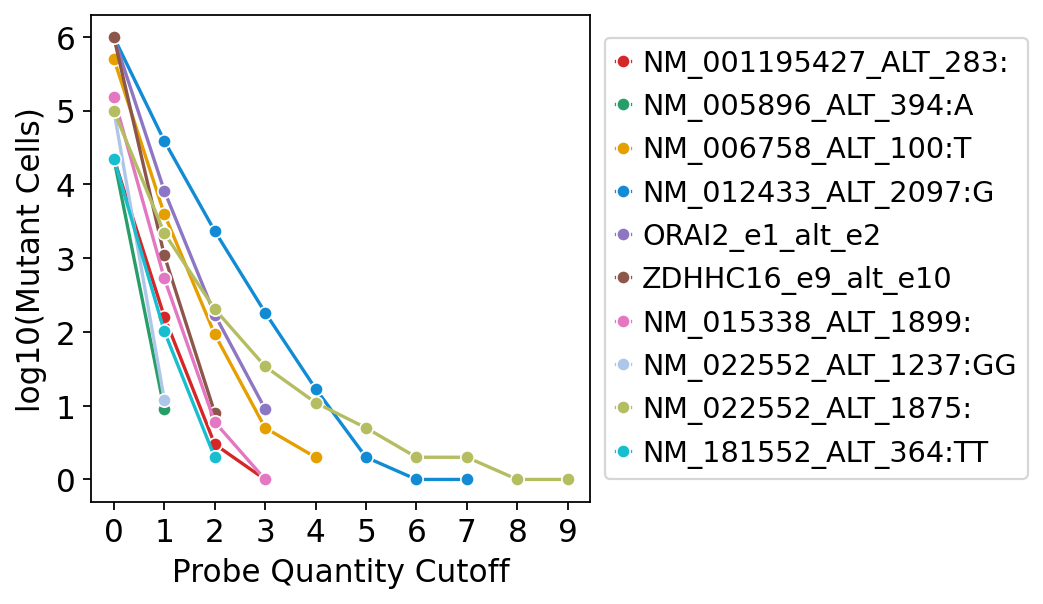

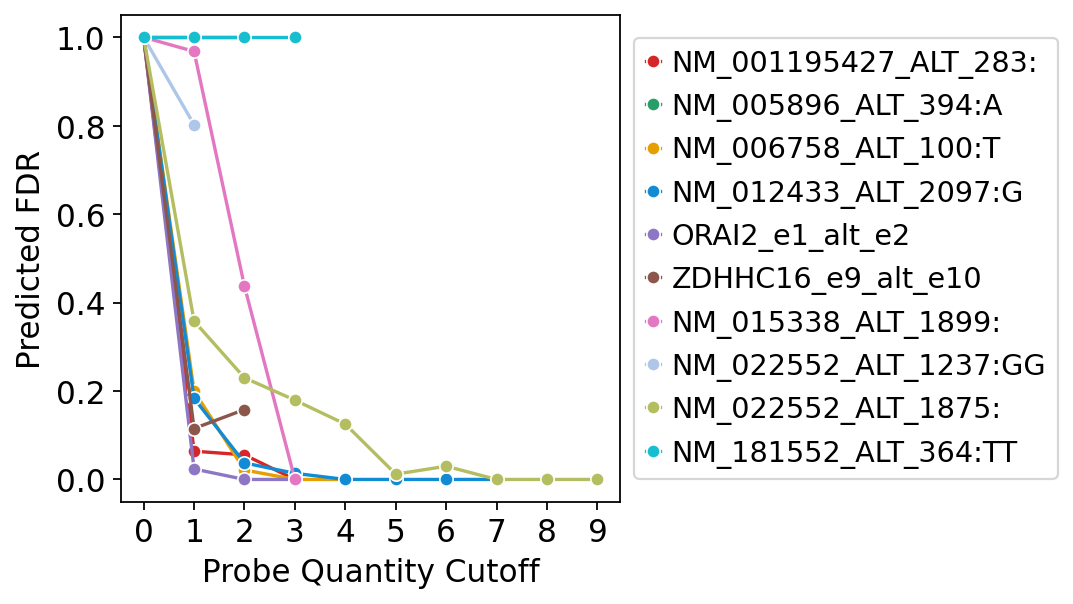

In [131]:
sc.set_figure_params(figsize=(4, 4))
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
#df = df_probe
df_probe.reset_index(drop=True, inplace=True)
df_probe['cutoff'] = [int(x) for x in df_probe['Probe Quantity Cutoff']]
df_probe['log10(Mutant Cells)'] = np.log10(df_probe['Mutant Cells'])
cmp = ['#d62728' , '#279e68',"#E69F00", "#118cd4", "#8d76c4", '#8c564b', '#e377c2', '#aec7e8', '#b5bd61', '#17becf']

sns.lineplot(data=df_probe, x="Probe Quantity Cutoff", y="log10(Mutant Cells)", hue = 'Mutant Probe', marker='o', palette = cmp)

plt.grid(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.show()

sns.lineplot(data=df, x="Probe Quantity Cutoff", y="Predicted FDR", hue = 'Mutant Probe', marker='o',palette = cmp)
plt.grid(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()

## ED Figure 11l-n. DEG analysis for volcano plots


In [35]:
## SF3B1 mutant vs control Mk DEG
sample_mutation_di = {'U2AF1': ['region1_0033266','region1_0065644','region2_0065644','region1_0065647','region2_0065647'], 'ASXL1': ['region1_0033266'],
                      'IDH1': ['region1_0033082'], 'SRSF2': ['region1_0033082'], 'CUX1': ['region1_0033082'],
                      'DNMT3A': ['region1_0033134'], 'SF3B1': ['region1_0033274', 'region1_0033485', 'region2_0043245', 'region2_0043233', 'region1_0065586']}

ct =  'Megakaryocyte'
samples = sample_mutation_di['SF3B1']
allmut = adata_xenv2[(adata_xenv2.obs['mutant'] == 'Yes') & (adata_xenv2.obs['ct_general'] == ct)]
allmut = allmut[allmut.obs['sample_name'].isin(samples)]

ctl_ad = adata_xenv2[adata_xenv2.obs['ct_general'] == ct]
ctl_ad = ctl_ad[ctl_ad.obs['sample_name'].isin(['region1_0032837','region2_0065574','region3_0065574','region4_0065586'])]

megas = [x for x in allmut.obs.index] + [x for x in ctl_ad.obs.index]
ad_mega = adata_xenv2[adata_xenv2.obs.index.isin(megas)]

ad_mega.obs['patient_id'] = [x.split('T1')[0] for x in ad_mega.obs['patient_id']]

res = runDEseq(
    ad_mega, 
    patient_col = 'patient_id', 
    condition_col = 'mutant',
    cond_1 = 'No',
    cond_2 = 'Yes',
    paired = False,
    min_cells_per_sample=25,
    gene_filter = 0.5)

res = res.sort_values(by='padj')
res


Dropping 2 patient(s) with < 25 cells.
A2M       6
ACE2      5
ACTA2     6
ACTB      6
ADAM28    6
         ..
VSIG4     5
VSIR      6
VWF       6
XBP1      6
ZNF683    5
Length: 431, dtype: int64
(6, 431)
No     3
Yes    3
Name: mutant, dtype: int64


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.29 seconds.

Fitting dispersion trend curve...
... done in 0.03 seconds.

Fitting MAP dispersions...
... done in 0.29 seconds.

Fitting LFCs...
... done in 0.25 seconds.

Refitting 0 outliers.

Running Wald tests...


Log2 fold change & Wald test p-value: mutant Yes vs No
           baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A2M       26.364922        0.184256  0.615776  0.299226  0.764768  0.877745
ACE2       5.163941       -2.977147  1.220660 -2.438964  0.014729       NaN
ACTA2    749.215669        1.722610  0.431976  3.987742  0.000067  0.004042
ACTB    2597.617515        1.115151  0.389034  2.866462  0.004151  0.049086
ADAM28     7.772925       -0.049743  0.878085 -0.056649  0.954824  0.985760
...             ...             ...       ...       ...       ...       ...
VSIG4      8.820007        1.521737  0.870194  1.748734  0.080337  0.270468
VSIR     313.501965        0.582991  0.435510  1.338637  0.180689  0.427724
VWF      653.959979        0.598288  0.467572  1.279563  0.200699  0.453819
XBP1     230.178876        0.456042  0.413150  1.103815  0.269673  0.514553
ZNF683     3.558373       -3.369591  1.568360 -2.148481  0.031676       NaN

[431 rows x 6 columns]


... done in 0.22 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
EGR3,14.813234,-5.681455,1.160384,-4.896183,9.771590e-07,0.000148
CCL5,166.390889,2.384014,0.485449,4.910946,9.063823e-07,0.000148
CD44,30.848788,-2.479217,0.577049,-4.296369,1.736188e-05,0.001754
AHSP,84.686289,2.098072,0.504899,4.155432,3.246730e-05,0.002459
ACTA2,749.215669,1.722610,0.431976,3.987742,6.670528e-05,0.004042
...,...,...,...,...,...,...
TFF3,2.068496,-0.076926,1.470260,-0.052321,9.582726e-01,NaN
TMPRSS2,3.690004,-2.455896,1.390487,-1.766213,7.736018e-02,NaN
TOX,3.582858,-1.506456,1.196337,-1.259224,2.079495e-01,NaN
TREM2,6.225931,0.256137,0.975824,0.262483,7.929490e-01,NaN


In [37]:
## Mk near vs far MSC DEG
ad_tmp = adata_xenv2[adata_xenv2.obs['ct_general'] == 'Mesenchymal/Stromal']
meganeighs = set()
for clust in ad_tmp.obs['mega_neigh']:
    if not clust == 'NA':
        for c in clust.split(','):
            meganeighs.add(c)

ad_tmp = adata_xenv2[adata_xenv2.obs['ct_general'] == 'Megakaryocyte']
ad_tmp = ad_tmp[~(ad_tmp.obs['sample_name'].isin(['region1_0032837','region2_0065574','region3_0065574','region4_0065586']))] #sparse samples
ad_tmp.obs['neigh'] = 'No'
ad_tmp.obs.loc[ad_tmp.obs.index.isin(meganeighs),'neigh'] = 'Yes'

res = runDEseq(
    ad_tmp, 
    patient_col = 'patient_id', 
    condition_col = 'neigh',
    cond_1 = 'No',
    cond_2 = 'Yes',
    paired = True,
    min_cells_per_sample=25,
    gene_filter = 0.5)

res = res.sort_values(by='padj')
res

Removing 0 unpaired samples
ND158_Yes      1035
ND158_No        888
ND72_T3_Yes     768
ND179_No        746
ND179_Yes       644
ND150_Yes       517
ND72_T3_No      463
ND83_Yes        425
ND72_T2_Yes     386
ND150_No        350
ND191_No        324
ND72_T1_Yes     321
ND83_No         307
ND226_Yes       297
ND226_No        252
ND72_T2_No      245
ND72_T4_No      239
ND72_T4_Yes     237
ND72_T1_No      200
ND72_T5_Yes     143
ND72_T5_No      114
ND191_Yes       110
ND170_Yes        94
ND62_Yes         81
ND170_No         59
ND62_No          48
Name: sample_group, dtype: int64

Retaining 26 / 26 patient-condition pairs with >= 25 cells.
13 unique patients across 26 pseudobulk rows (patient-blocked design will spend ~13 degrees of freedom on patient identity alone).
A2M       26
ACE2      25
ACTA2     26
ACTB      26
ADAM28    25
          ..
VSIG4     24
VSIR      26
VWF       26
XBP1      26
ZNF683    24
Length: 431, dtype: int64
(26, 431)
No     13
Yes    13
Name: neigh, dtype: int64


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.31 seconds.

Fitting dispersion trend curve...
... done in 0.04 seconds.

Fitting MAP dispersions...
... done in 0.32 seconds.

Fitting LFCs...
... done in 0.28 seconds.

Refitting 0 outliers.

Running Wald tests...


Log2 fold change & Wald test p-value: neigh Yes vs No
           baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A2M       62.890091       -0.488789  0.217576 -2.246526  0.024670  0.129285
ACE2       7.655738       -0.334320  0.276850 -1.207583  0.227208  0.482168
ACTA2    888.572862        0.278517  0.158328  1.759113  0.078558  0.272450
ACTB    3563.550750        0.343478  0.159789  2.149569  0.031589  0.148613
ADAM28    17.817784        0.134195  0.241242  0.556268  0.578028  0.774804
...             ...             ...       ...       ...       ...       ...
VSIG4     15.822577        0.130277  0.201629  0.646123  0.518200  0.737232
VSIR     311.325891        0.281810  0.115688  2.435957  0.014852  0.102482
VWF     1073.784808        0.397188  0.116396  3.412369  0.000644  0.012001
XBP1     315.109004        0.176476  0.101546  1.737887  0.082231  0.272450
ZNF683     4.378521       -0.499340  0.333201 -1.498616  0.133973  0.364199

[431 rows x 6 columns]


... done in 0.22 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
CXCL12,819.167113,0.825312,0.077421,10.660005,1.565888e-26,6.482775e-24
CD44,99.232555,-1.982264,0.267203,-7.418565,1.183962e-13,2.450801e-11
NCAM1,38.936586,-1.974668,0.284867,-6.931884,4.152720e-12,5.730753e-10
LEPR,122.355193,0.551833,0.084132,6.559134,5.412108e-11,5.601532e-09
CD276,36.109196,-1.236354,0.209095,-5.912887,3.361637e-09,2.783435e-07
...,...,...,...,...,...,...
FOS,2.182349,0.160800,0.459310,0.350090,7.262709e-01,NaN
GZMB,2.093083,0.074076,0.468784,0.158016,8.744439e-01,NaN
IFNL1,0.779347,0.249605,0.724609,0.344468,7.304945e-01,NaN
PDCD1,0.976937,-0.405375,0.612334,-0.662017,5.079601e-01,NaN


In [40]:
## SF3B1 mutant vs control Late/Mature Myeloid DEG
sample_mutation_di = {'U2AF1': ['region1_0033266','region1_0065644','region2_0065644','region1_0065647','region2_0065647'], 'ASXL1': ['region1_0033266'],
                      'IDH1': ['region1_0033082'], 'SRSF2': ['region1_0033082'], 'CUX1': ['region1_0033082'],
                      'DNMT3A': ['region1_0033134'], 'SF3B1': ['region1_0033274', 'region1_0033485', 'region2_0043245', 'region2_0043233', 'region1_0065586']}

ct =  'Late/Mature Myeloid'
samples = sample_mutation_di['SF3B1']
allmut = adata_xenv2[(adata_xenv2.obs['mutant'] == 'Yes') & (adata_xenv2.obs['ct_general'] == ct)]
allmut = allmut[allmut.obs['sample_name'].isin(samples)]

ctl_ad = adata_xenv2[adata_xenv2.obs['ct_general'] == ct]
ctl_ad = ctl_ad[ctl_ad.obs['sample_name'].isin(['region1_0032837','region2_0065574','region3_0065574','region4_0065586'])]

mye = [x for x in allmut.obs.index] + [x for x in ctl_ad.obs.index]
ad_mye = adata_xenv2[adata_xenv2.obs.index.isin(mye)]

ad_mye.obs['patient_id'] = [x.split('T1')[0] for x in ad_mye.obs['patient_id']]

res = runDEseq(
    ad_mye, 
    patient_col = 'patient_id', 
    condition_col = 'mutant',
    cond_1 = 'No',
    cond_2 = 'Yes',
    paired = False,
    min_cells_per_sample=25,
    gene_filter = 0.5)

res = res.sort_values(by='padj')
res


A2M       8
ACE2      6
ACTA2     8
ACTB      8
ADAM28    7
         ..
VSIG4     8
VSIR      8
VWF       7
XBP1      8
ZNF683    7
Length: 429, dtype: int64
(8, 429)
Yes    5
No     3
Name: mutant, dtype: int64


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 1.32 seconds.

Fitting dispersion trend curve...
... done in 0.04 seconds.

Fitting MAP dispersions...
... done in 1.28 seconds.

Fitting LFCs...
... done in 0.26 seconds.

Refitting 0 outliers.

Running Wald tests...


Log2 fold change & Wald test p-value: mutant Yes vs No
           baseMean  log2FoldChange     lfcSE      stat        pvalue  \
A2M       45.124127        0.964025  0.417591  2.308539  2.096915e-02   
ACE2       8.102380       -2.235092  0.866071 -2.580725  9.859310e-03   
ACTA2    507.587868        2.057503  0.410484  5.012378  5.376138e-07   
ACTB    3163.845330        1.961361  0.467627  4.194282  2.737375e-05   
ADAM28    30.250921       -1.358743  0.430962 -3.152813  1.617053e-03   
...             ...             ...       ...       ...           ...   
VSIG4     35.179308        1.220906  0.427682  2.854703  4.307706e-03   
VSIR     786.953629        0.114945  0.257954  0.445602  6.558844e-01   
VWF       16.668960        0.049723  0.625441  0.079501  9.366339e-01   
XBP1     168.880276        0.344837  0.303612  1.135780  2.560486e-01   
ZNF683     4.740199       -0.578988  0.914611 -0.633043  5.267054e-01   

            padj  
A2M     0.080476  
ACE2    0.048334  
ACTA2   0.0

... done in 0.22 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
HEMGN,222.877306,1.773785,0.251401,7.055592,1.718670e-12,7.321536e-10
CEACAM6,1023.957220,1.510742,0.266059,5.678221,1.361030e-08,1.932663e-06
CTSD,733.538866,1.476896,0.257484,5.735884,9.700498e-09,1.932663e-06
VCAM1,251.432112,1.988977,0.376298,5.285649,1.252597e-07,1.183154e-05
ALAS2,601.393136,1.958024,0.371772,5.266740,1.388678e-07,1.183154e-05
...,...,...,...,...,...,...
SYK,626.577584,0.000325,0.260251,0.001248,9.990039e-01,9.990039e-01
CD3D,17.504163,0.001143,0.556051,0.002055,9.983606e-01,9.990039e-01
CCR4,39.145369,0.421740,1.237677,0.340751,NaN,NaN
IGHG2,51.702843,-0.495486,0.789918,-0.627263,NaN,NaN
